# ViT

## Check GPU

In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA compiled:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: C:\Users\user\anaconda3\envs\monai\python.exe
PyTorch: 2.11.0+cu128
CUDA compiled: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 5070


## Random Seed

In [2]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# More deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Random seed: {SEED}")

Random seed: 42


## Imports

In [3]:
import os
import torch
import time
import timm
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

C:\Users\user\anaconda3\envs\monai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset paths

In [4]:
data_dir = r"C:\Users\user\Desktop\MONAI\data\brain-tumor-mri-classification\merged_dataset_v3\images"

train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

## Image transformations

In [5]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## Load datasets

In [6]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

print("Classes:", train_dataset.classes)
print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Train: 8306
Val: 488
Test: 246


## DataLoaders

In [7]:
g = torch.Generator()
g.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    generator=g
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

## Create the ViT model with timm

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=4
)

model = model.to(device)

print(model)

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

## Loss and optimizer

In [9]:
import torch.optim as optim

criterion = torch.nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

## Training loop

In [10]:
num_epochs = 50

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    epoch_start = time.time()

    # =========================
    # TRAINING
    # =========================
    
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total


    # =========================
    # VALIDATION
    # =========================
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / total
    val_accuracy = correct / total


    # =========================
    # STORE METRICS
    # =========================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    epoch_time = time.time() - epoch_start


    # =========================
    # PRINT
    # =========================

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

Epoch [1/50] | Train Loss: 0.6679 | Train Acc: 0.7304 | Val Loss: 0.2588 | Val Acc: 0.9057 | Time: 75.07s
Epoch [2/50] | Train Loss: 0.1955 | Train Acc: 0.9293 | Val Loss: 0.1803 | Val Acc: 0.9344 | Time: 75.04s
Epoch [3/50] | Train Loss: 0.1159 | Train Acc: 0.9600 | Val Loss: 0.0708 | Val Acc: 0.9754 | Time: 75.07s
Epoch [4/50] | Train Loss: 0.0806 | Train Acc: 0.9734 | Val Loss: 0.0883 | Val Acc: 0.9754 | Time: 75.51s
Epoch [5/50] | Train Loss: 0.0691 | Train Acc: 0.9753 | Val Loss: 0.1012 | Val Acc: 0.9754 | Time: 75.91s
Epoch [6/50] | Train Loss: 0.0592 | Train Acc: 0.9803 | Val Loss: 0.1223 | Val Acc: 0.9549 | Time: 75.07s
Epoch [7/50] | Train Loss: 0.0527 | Train Acc: 0.9821 | Val Loss: 0.2545 | Val Acc: 0.8996 | Time: 75.14s
Epoch [8/50] | Train Loss: 0.0627 | Train Acc: 0.9791 | Val Loss: 0.0609 | Val Acc: 0.9713 | Time: 76.13s
Epoch [9/50] | Train Loss: 0.0380 | Train Acc: 0.9860 | Val Loss: 0.0453 | Val Acc: 0.9836 | Time: 76.35s
Epoch [10/50] | Train Loss: 0.0441 | Train Acc

## Save the ViT checkpoint

In [11]:
torch.save(
    model.state_dict(),
    "../models/vit_base_patch16_224.pt"
)

## Accuracy and loss curves

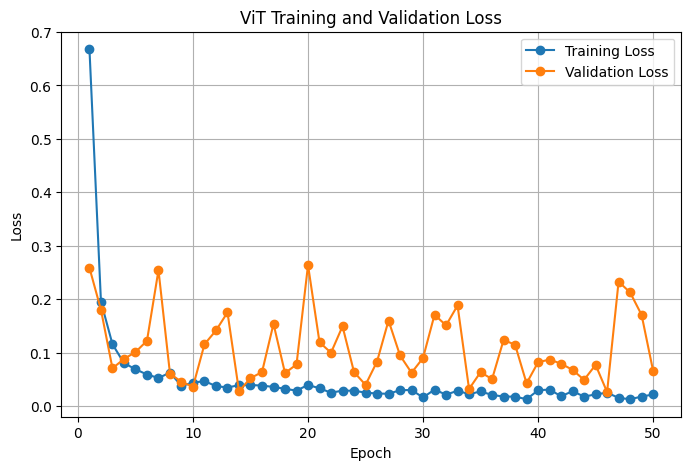

In [12]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

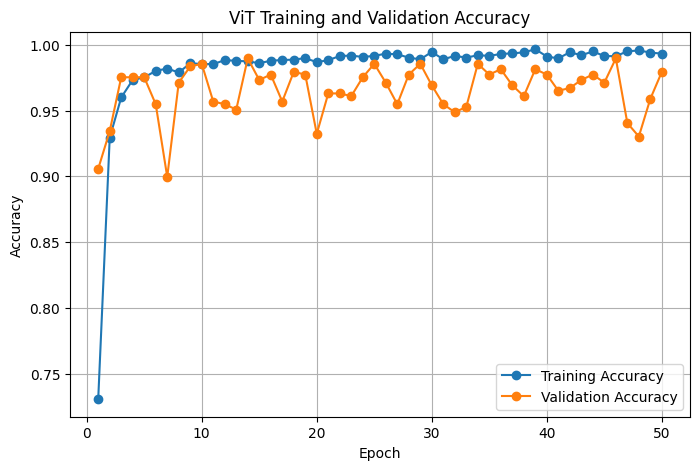

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ViT Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## Test-set evaluation

In [14]:
model.eval()

all_labels = []
all_predictions = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(
            predictions.cpu().numpy()
        )

In [15]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.9797
Precision: 0.9801
Recall   : 0.9797
F1 Score : 0.9797


## Classification report

In [16]:
class_names = train_dataset.classes

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      glioma       0.96      1.00      0.98        81
  meningioma       0.96      0.96      0.96        55
    no_tumor       1.00      0.98      0.99        49
   pituitary       1.00      0.97      0.98        61

    accuracy                           0.98       246
   macro avg       0.98      0.98      0.98       246
weighted avg       0.98      0.98      0.98       246



## Confusion matrix

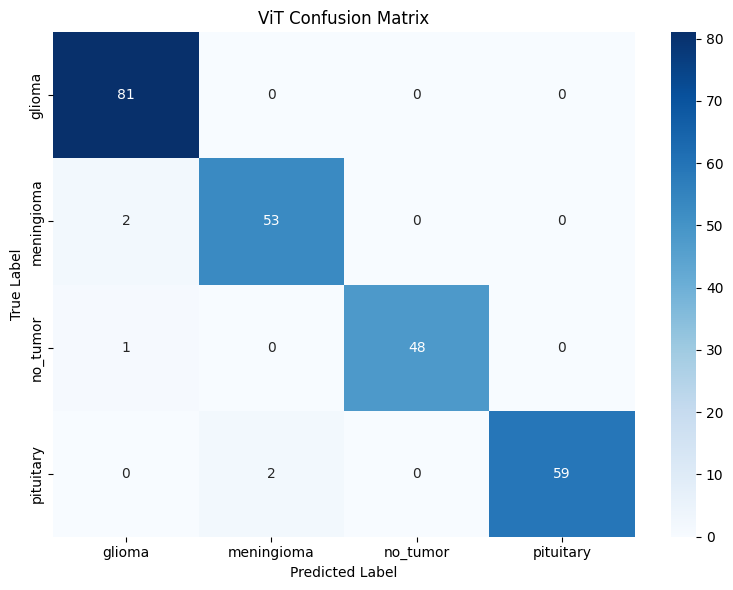

In [20]:
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ViT Confusion Matrix")
plt.tight_layout()
plt.show()